# When was the animal running, and which traversals were fully observed?

**Question:** Which running bouts and left-to-right track traversals can we
measure without joining observations across a tracking dropout?

**You will need:** Tracking positions and timestamps, the measured track
centerline, and end-zone definitions. We provide four simulated out-and-back
cycles with pauses and a one-second dropout during one left-to-right pass.

**Estimated time**: 20-25 minutes

**Prerequisites**: [01: occupancy](01_getting_started.ipynb).

We will express position as distance along the track, identify running bouts,
and compare the time courses of complete traversals. These behavioral windows
can then be used for firing-rate analysis. The notebook runs independently
and requires no downloads.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from shapely.geometry import Point

from neurospatial import Environment
from neurospatial.behavior import (
    compute_step_lengths,
    detect_region_crossings,
    detect_runs_between_regions,
    path_progress,
    segment_by_velocity,
)
from neurospatial.regions import Regions

_here = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
if not (_here / "_style.py").exists() and (_here / "examples" / "_style.py").exists():
    _here = _here / "examples"
if str(_here) not in sys.path:
    sys.path.insert(0, str(_here))
from _style import apply_style

apply_style(figsize=(11, 5))

## 1. Express position as distance along the track

The animal runs on a 100 cm L-shaped track. Linearized position measures
distance from the left end along the bend, so movement on both arms can be
shown on one position axis. We divide that distance into 2 cm bins.

Define the centerline from the apparatus coordinates in `node_positions`.
`linear_track()` keeps both this 2D description and the distance along it.
`edge_spacing=0` keeps distance continuous at the corner. `track_width` is
the measured width of the 10 cm corridor: a position farther than 5 cm from
the centerline is off the track and gets no bin. The circles have an 8 cm
radius and define the end zones for left-to-right traversals below.

In [2]:
track = Environment.linear_track(
    node_positions=[(0.0, 0.0), (60.0, 0.0), (60.0, 40.0)],
    bin_size=2.0,
    edge_spacing=0.0,
    track_width=10.0,
    units="cm",
    frame="track",
    name="Bent shuttle track",
)
regions = Regions(track.regions.values())
regions.add("left", polygon=Point(2.0, 0.0).buffer(8.0))
regions.add("right", polygon=Point(60.0, 38.0).buffer(8.0))
track = track.with_regions(regions)

In [3]:
# Generate repeated traversals with variation in running duration and pause length.
rng = np.random.default_rng(303)
knot_times, knot_distances = [0.0, 1.5], [2.0, 2.0]
for _ in range(4):
    for destination, duration in [
        (98.0, rng.uniform(4.0, 7.0)),
        (98.0, rng.uniform(1.2, 2.0)),
        (2.0, rng.uniform(4.0, 7.0)),
        (2.0, rng.uniform(1.2, 2.0)),
    ]:
        knot_times.append(knot_times[-1] + duration)
        knot_distances.append(destination)

full_times = np.arange(0.0, knot_times[-1], 0.02)
distance = np.interp(full_times, knot_times, knot_distances)
full_positions = track.linear_to_nd(distance)
full_positions += rng.normal(0.0, 0.02, size=full_positions.shape)

# Remove one second from the middle of the second left-to-right traversal.
gap_center = (knot_times[5] + knot_times[6]) / 2
keep = np.abs(full_times - gap_center) > 0.5
times, positions = full_times[keep], full_positions[keep]

Tracking samples: 2,923; spatial bins along the track: 50
Distance from tracking to centerline, 95th percentile: 0.04 cm


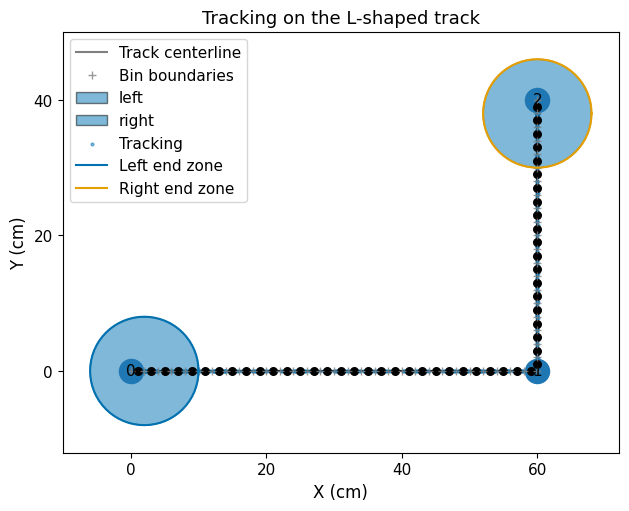

In [4]:
linear_position = track.to_linear(positions)
projected = track.linear_to_nd(linear_position)
residual = np.linalg.norm(positions - projected, axis=1)
position_bins = track.bin_at(positions)
assert np.all(position_bins >= 0) and np.all(np.diff(times) > 0)
print(f"Tracking samples: {len(times):,}; spatial bins along the track: {track.n_bins}")
print(
    f"Distance from tracking to centerline, 95th percentile: {np.percentile(residual, 95):.2f} cm"
)

fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
track.plot(ax=ax)
ax.scatter(*positions[::5].T, s=4, alpha=0.5, label="Tracking")
for name in ["left", "right"]:
    boundary_x, boundary_y = track.regions[name].data.exterior.xy
    ax.plot(boundary_x, boundary_y, label=f"{name.capitalize()} end zone")
ax.set(xlabel="X (cm)", ylabel="Y (cm)", title="Tracking on the L-shaped track")
ax.set_xticks([0, 20, 40, 60])
ax.set_yticks([0, 20, 40])
ax.tick_params(bottom=True, left=True, labelbottom=True, labelleft=True)
handles, labels = ax.get_legend_handles_labels()
legend_entries = {
    {"original edges": "Track centerline", "bin edges": "Bin boundaries"}.get(
        label, label
    ): handle
    for label, handle in zip(labels, handles)
}
ax.legend(legend_entries.values(), legend_entries, loc="upper left")
ax.set_aspect("equal")
plt.show()

Tracking stays close to the defined centerline: 95% of positions are within
about 0.04 cm in this simulation. With camera data, inspect departures from
the centerline before accepting linearized position. Large differences can
indicate calibration errors or off-track positions. On a branching maze,
assigning the nearest track segment can also select the wrong arm.

## 2. Identify running bouts while excluding the tracking gap

Calculate speed from changes in the tracked 2D position and elapsed time.
This avoids the jumps caused by calculating speed from spatial-bin indices.
Tracking samples are 20 ms apart; intervals longer than 100 ms are excluded
from speed and occupancy because movement during them was not observed.

We smooth speed over 100 ms. A running bout starts above 8 cm/s and ends below
4 cm/s, with a minimum duration of 0.5 s. The two thresholds reduce repeated
starts and stops near the cutoff; `hysteresis=2` sets their ratio.

In [5]:
intervals = np.diff(times)
observed_interval = intervals <= 0.1
step_lengths = compute_step_lengths(positions)
speed = np.where(observed_interval, step_lengths / intervals, np.nan)
occupancy = track.occupancy(times, positions, max_gap=0.1)
print(f"Time from first to last tracking sample: {times[-1] - times[0]:.2f} s")
print(f"Time with continuous tracking: {occupancy.sum():.2f} s")
print(f"Intervals excluded for missing tracking: {(~observed_interval).sum()}")
assert np.isclose(occupancy.sum(), intervals[observed_interval].sum())

movement = segment_by_velocity(
    times,
    positions,
    min_speed=8.0,
    hysteresis=2.0,
    min_duration=0.5,
    smooth_window=0.1,
    max_gap=0.1,
)
print(f"Running bouts: {len(movement)}")

Time from first to last tracking sample: 59.44 s
Time with continuous tracking: 58.42 s
Intervals excluded for missing tracking: 1
Running bouts: 9


The detector returns nine bouts. The dropout splits one planned traversal
into two separately observed running periods. Small tracking noise affects
speed near pauses, so the speed trace below is useful for checking the chosen
thresholds before applying them to a real recording.

## 3. Measure left-to-right traversals

A traversal begins at the first sample outside the left end zone and ends
at the first sample inside the right end zone. Allow up to 12 s to reach the
right zone. A tracking gap ends the observed segment before arrival.
End-zone membership uses 2 cm bin centers, so event times depend on both
tracking frequency and spatial bin width.

Entries into the right end zone: 4
Left-to-right traversals: 3 complete; 1 incomplete
  1: 1.90-5.76 s; reached
  2: 16.06-18.24 s; censored
  3: 30.82-34.66 s; reached
  4: 43.44-49.08 s; reached


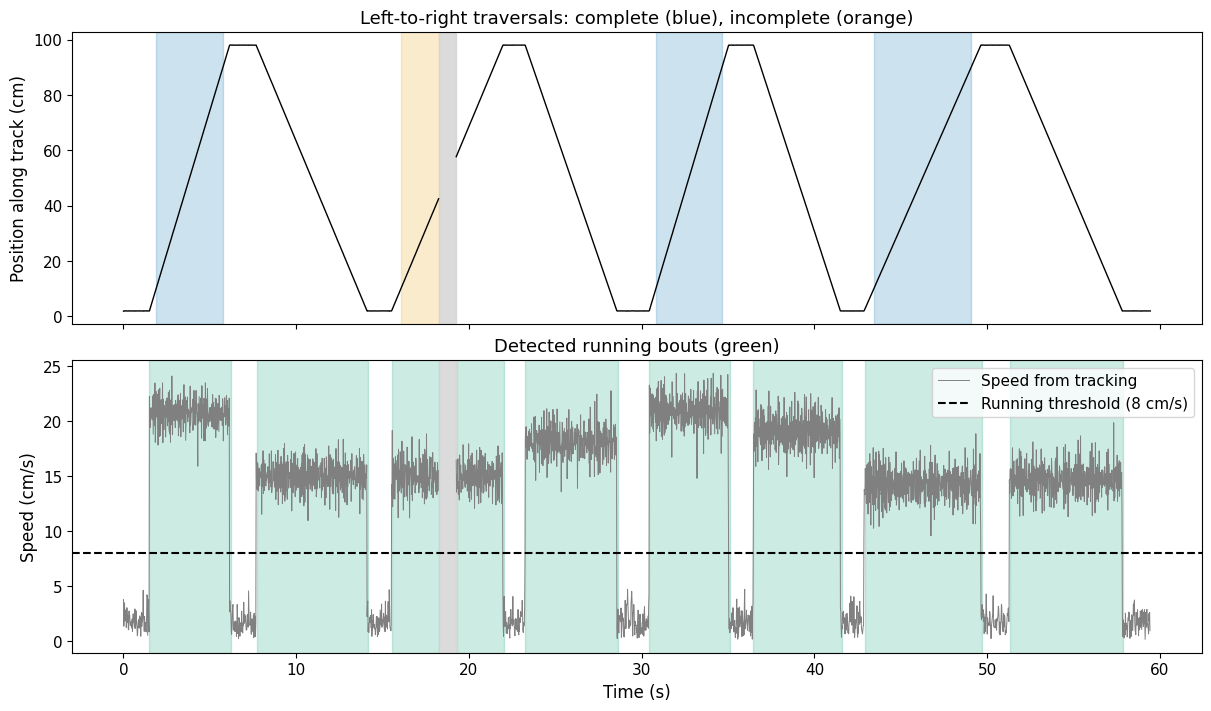

In [6]:
entries = detect_region_crossings(
    position_bins, times, track, region_name="right", direction="entry", max_gap=0.1
)
runs = detect_runs_between_regions(
    position_bins,
    times,
    track,
    source="left",
    target="right",
    min_duration=0.5,
    max_duration=12.0,
    max_gap=0.1,
)
complete_runs = [run for run in runs if run.success]
print(f"Entries into the right end zone: {len(entries)}")
print(
    f"Left-to-right traversals: {len(complete_runs)} complete; {len(runs) - len(complete_runs)} incomplete"
)
for number, run in enumerate(runs, start=1):
    print(f"  {number}: {run.start_time:.2f}-{run.end_time:.2f} s; {run.outcome}")

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, layout="constrained")
# Draw each continuous recording period separately, leaving the tracking gap empty.
chunks = np.split(np.arange(len(times)), np.flatnonzero(~observed_interval) + 1)
for chunk in chunks:
    axes[0].plot(times[chunk], linear_position[chunk], color="black", lw=1)
for run in runs:
    axes[0].axvspan(
        run.start_time,
        run.end_time,
        color="#0072B2" if run.success else "#E69F00",
        alpha=0.2,
    )
axes[0].set(
    ylabel="Position along track (cm)",
    title="Left-to-right traversals: complete (blue), incomplete (orange)",
)
axes[1].plot(times[:-1], speed, lw=0.7, color="gray", label="Speed from tracking")
for start, stop in movement:
    axes[1].axvspan(start, stop, color="#009E73", alpha=0.2)
axes[1].axhline(8.0, color="black", ls="--", label="Running threshold (8 cm/s)")
axes[1].set(
    xlabel="Time (s)", ylabel="Speed (cm/s)", title="Detected running bouts (green)"
)
axes[1].legend(loc="upper right")
for ax in axes:
    ax.axvspan(gap_center - 0.5, gap_center + 0.5, color="lightgray", alpha=0.8)
plt.show()

The upper plot shows three complete traversals in blue. The orange segment
ends at the gray tracking gap. We still observe four entries into the right
zone: seeing an arrival after the gap does not recover the missing part of
that journey. The lower plot shows running bouts in both directions, separated
by pauses and the same tracking gap. Its speed trace is unsmoothed; bout
detection uses 100 ms smoothing, so the green boundaries need not match
crossings of the threshold in the displayed trace exactly.

Each run records its `outcome`: `"reached"` means that arrival was observed
within the time limit, and `run.success` is shorthand for that. `"censored"`
means observation stopped first (here, at the tracking gap), so the result
is unknown; `"timeout"` and `"returned"` mark a run that ran out of time or
went back to the left zone. The outcome does not describe reward or task
accuracy. Keep the censored segment when reporting how much behavior could
be measured, and leave it out of success rates.

## 4. Compare position over the course of complete traversals

Put each complete traversal on a common scale with `path_progress()`: 0 in
the left end zone, 1 in the right end zone. It is computed once for the
whole session, from the left zone to the right zone. On a track like this
one, with a single route between the zones, progress is the fraction of
the route's length covered: 0.5 is halfway along the track. (On a maze
with side arms, a wrong arm keeps the value of the junction where it
leaves the route.)

A run is the half-open window `[start, stop)`: it stops at the first sample
inside the right zone, the arrival, which is just outside the run. To draw
curves that land on 1, plot each run's samples plus that arrival sample.
Scale elapsed time by each traversal's duration as well, to compare the
shape of the movement across traversals of different lengths in seconds.
The 2 cm spatial bins create small steps in the curves.

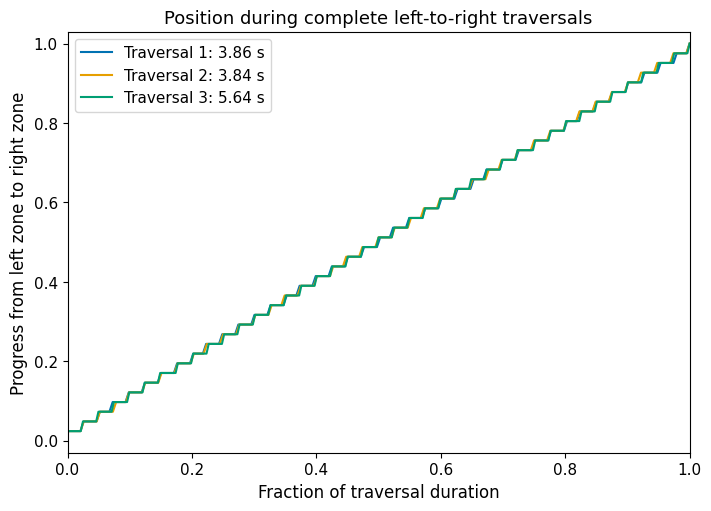

In [7]:
progress = path_progress(track, times, positions, start="left", goal="right")

fig, ax = plt.subplots(figsize=(7, 5), layout="constrained")
for number, run in enumerate(complete_runs, start=1):
    first, arrival = np.searchsorted(times, [run.start_time, run.end_time])
    shown = slice(first, arrival + 1)  # the run's samples and its arrival
    run_times = times[shown]
    relative_time = (run_times - run_times[0]) / (run_times[-1] - run_times[0])
    ax.plot(
        relative_time,
        progress[shown],
        label=f"Traversal {number}: {run_times[-1] - run_times[0]:.2f} s",
    )
ax.set(
    xlabel="Fraction of traversal duration",
    ylabel="Progress from left zone to right zone",
    title="Position during complete left-to-right traversals",
    xlim=(0, 1),
    ylim=(-0.03, 1.03),
)
ax.legend()
plt.show()

The curves mostly overlap because the simulated traversals have approximately
constant speed. Their durations differ, as shown in the legend; scaling time
removes those duration differences from the horizontal axis. Each curve
starts just above 0, at the first sample outside the left zone, and ends at
1, the arrival. Use the earlier time trace when comparing absolute running
times.

Progress describes position along the route. It decreases with
backtracking, unlike cumulative distance traveled. The track fixes the route
in this example. Interpreting goal-directed choices would require a task with
alternatives and evidence about the animal's choices.

## Use your own recording

Replace `times` with tracking timestamps in seconds and `positions` with
sample-aligned `(x, y)` coordinates in calibrated physical units. Define the
track centerline and end zones from your apparatus. Inspect the 2D trace and
distances from the centerline before using linearized position.

Choose the running-speed thresholds, smoothing interval, minimum bout length,
and gap limit from the tracking noise and behavior in your recording. Report
the zone sizes and traversal timeout. Position-defined traversals need task
logs before they can be interpreted as rewarded trials or correct choices.

Running bouts and traversals provide `start_time` and `end_time` in seconds.
Pass the desired windows as `epochs=` for firing-rate analysis, using the same
windows for spikes and occupancy. These analysis windows are half-open
`[start, stop)`; count arrival events separately if they fall at a window end.

Continue with [04: a hippocampal recording](04_real_data_analysis.ipynb), or see
the [behavior guide](https://edeno.github.io/neurospatial/user-guide/trajectory-and-behavioral-analysis/)
for region visits, circular laps, turn angles, and other movement measures.